# Student Marks Prediction using Simple Linear Regression

## Project Objective
The objective of this project is to predict a student's exam marks based on the number of hours they study.

## Machine Learning Algorithm
Simple Linear Regression

## Technologies Used
- Python
- NumPy
- Pandas
- Matplotlib
- Seaborn
- Scikit-learn

## Implementation
1. Data Collection
2. Exploratory Data Analysis (EDA)
3. Data Preprocessing
4. Model Training
5. Model Evaluation
6. Prediction

# 1 - Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


# 2 - Generate Dataset

In [3]:
np.random.seed(42)

hours = np.random.uniform(1, 9, 200)

noise = np.random.normal(0, 4, 200)

marks = 8 + (9 * hours) + noise

marks = np.clip(marks, 0, 100)

df = pd.DataFrame({
    "Hours": hours,
    "Marks": marks
})

df.head()

df.to_csv("data/student_scores.csv", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!


### 2.1 Load Dataset

In [4]:
df = pd.read_csv("data/student_scores.csv")

df.head()

,Hours,Marks
0,3.996321,41.246790
1,8.605714,86.380445
2,6.855952,70.875854
3,5.789268,57.246005
4,2.248149,35.696440


### 2.2 Dataset Information

In [5]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

Dataset Shape: (200, 2)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Hours   200 non-null    float64
 1   Marks   200 non-null    float64
dtypes: float64(2)
memory usage: 3.3 KB


# 3 - Data Cleaning

Missing Values:
Hours    0
Marks    0
dtype: int64
Duplicate Rows: 0


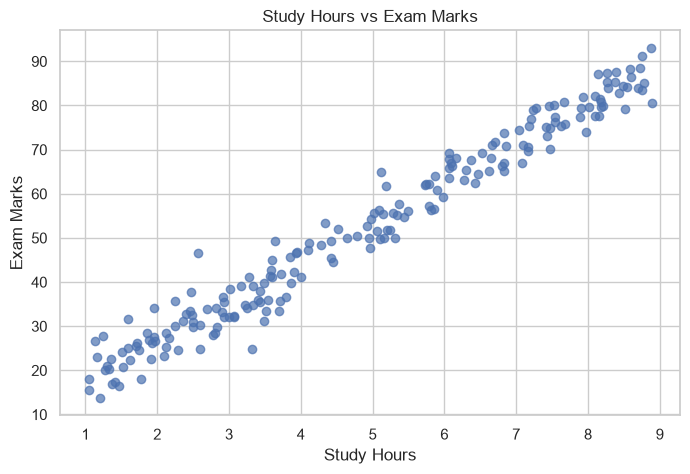

In [6]:
print("Missing Values:")
print(df.isnull().sum())

print("Duplicate Rows:", df.duplicated().sum())

plt.figure(figsize=(8, 5))

plt.scatter(
    df["Hours"],
    df["Marks"],
    alpha=0.7
)

plt.xlabel("Study Hours")
plt.ylabel("Exam Marks")
plt.title("Study Hours vs Exam Marks")

plt.show()

# 4 - Exploratory Data Analysis (EDA) & Data Preparation

### 4.1 Distribution of Study Hours and Marks

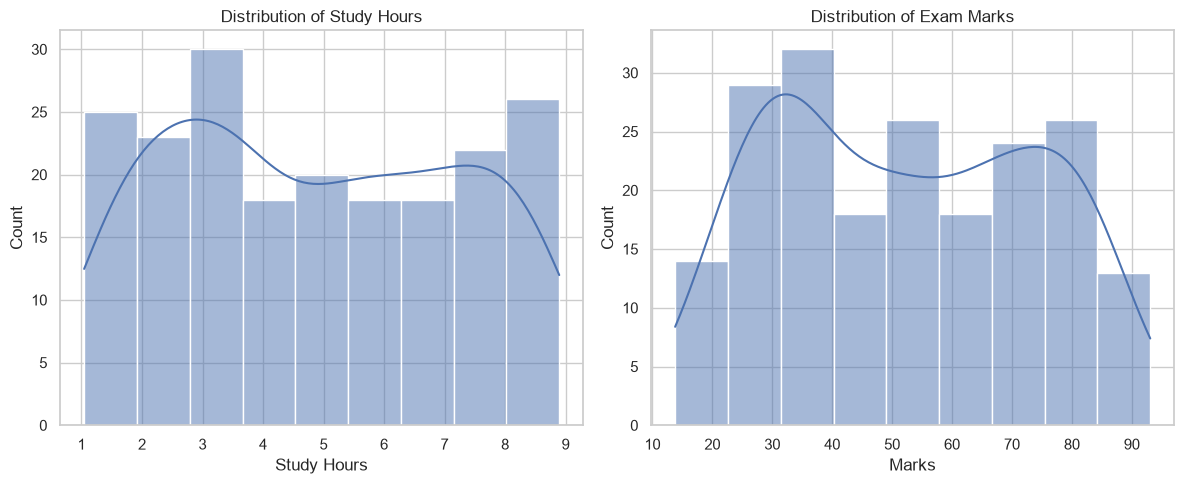

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(df["Hours"], kde=True, ax=axes[0])
axes[0].set_title("Distribution of Study Hours")
axes[0].set_xlabel("Study Hours")

sns.histplot(df["Marks"], kde=True, ax=axes[1])
axes[1].set_title("Distribution of Exam Marks")
axes[1].set_xlabel("Marks")

plt.tight_layout()
plt.show()

### 4.2 Correlation Analysis and Correlation Heatmap

Correlation between Hours and Marks: 0.9836114801702427


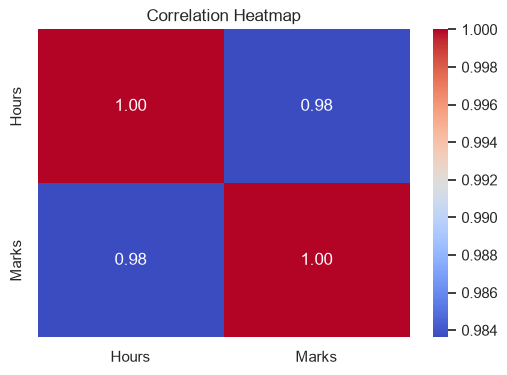

In [9]:
correlation = df["Hours"].corr(df["Marks"])

print("Correlation between Hours and Marks:", correlation)

plt.figure(figsize=(6, 4))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

### 4.3 Feature Selection

In [10]:
X = df[["Hours"]].values
y = df["Marks"].values

print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

Feature Shape: (200, 1)
Target Shape: (200,)


### 4.4 Train-Test Split

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (160, 1)
Testing Features: (40, 1)
Training Target: (160,)
Testing Target: (40,)


### 4.5 Visualize Train and Test Data

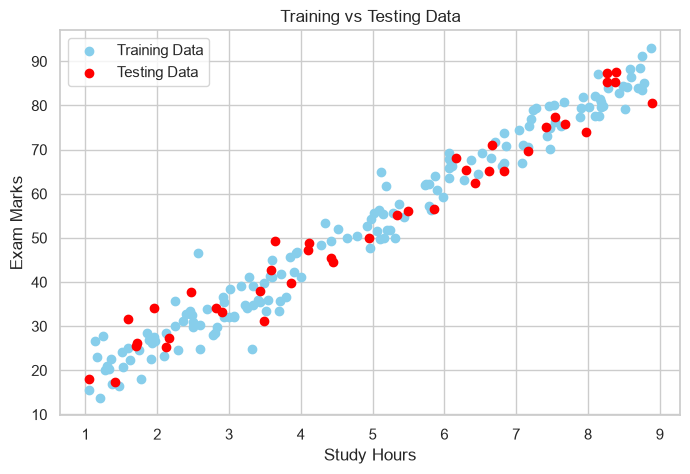

In [13]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_train,
    y_train,
    color="skyblue",
    label="Training Data"
)

plt.scatter(
    X_test,
    y_test,
    color="red",
    label="Testing Data"
)

plt.xlabel("Study Hours")
plt.ylabel("Exam Marks")
plt.title("Training vs Testing Data")

plt.legend()
plt.show()

### 4.6 Check Training Data

In [14]:
print("First 5 Training Samples:")

for i in range(5):
    print(f"Hours: {X_train[i][0]:.2f}, Marks: {y_train[i]:.2f}")

First 5 Training Samples:
Hours: 1.93, Marks: 26.21
Hours: 8.18, Marks: 80.74
Hours: 6.47, Marks: 64.48
Hours: 4.65, Marks: 49.89
Hours: 3.54, Marks: 35.97


# 5 - Linear Regression from Scratch using NumPy

### 5.1 Feature Scaling

In [15]:
x_mean = X_train.mean()
x_std = X_train.std()

X_train_scaled = (X_train - x_mean) / x_std
X_test_scaled = (X_test - x_mean) / x_std

print("Training mean:", x_mean)
print("Training standard deviation:", x_std)

Training mean: 4.854757642403632
Training standard deviation: 2.3522035558693353


### 5.2 Initialize Perameters

In [16]:
w = 0.0
b = 0.0

learning_rate = 0.05
epochs = 3000

n = len(X_train_scaled)

loss_history = []

### 5.3 Gradient Descent Implementation

In [17]:
X_train_1d = X_train_scaled.ravel()

for epoch in range(epochs):

    # Forward propagation
    y_pred = w * X_train_1d + b

    # Calculate error
    errors = y_pred - y_train

    # Calculate gradients
    dw = (2 / n) * np.sum(errors * X_train_1d)
    db = (2 / n) * np.sum(errors)

    # Update parameters
    w = w - learning_rate * dw
    b = b - learning_rate * db

    # Calculate Mean Squared Error
    loss = np.mean(errors ** 2)
    loss_history.append(loss)

print("Training completed!")
print("Weight:", w)
print("Bias:", b)
print("Final Loss:", loss_history[-1])

Training completed!
Weight: 21.292974069921307
Bias: 51.95277126279549
Final Loss: 14.395936192871755


### 5.4 Visualization Gradient Decent Lose

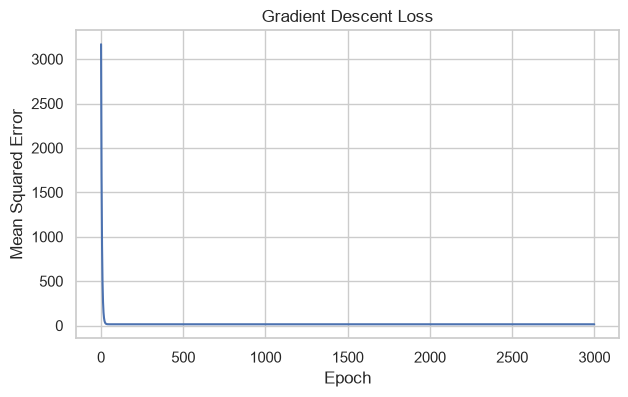

In [20]:
plt.figure(figsize=(7, 4))

plt.plot(loss_history)

plt.title("Gradient Descent Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")

plt.grid(True)
plt.show()

### 5.5 Predict Using Our Model

In [23]:
X_test_1d = X_test_scaled.ravel()

y_pred_scratch = w * X_test_1d + b

print("Actual values:", y_test[:5])
print("Predicted values:", y_pred_scratch[:5])


slope_scratch = w / x_std

intercept_scratch = b - (w * x_mean / x_std)

print("\n\nSlope:", slope_scratch)
print("Intercept:", intercept_scratch)

print(
    f"Regression Equation: Marks = "
    f"{slope_scratch:.2f} * Hours + {intercept_scratch:.2f}"
)

Actual values: [49.93996601 37.79229664 56.45965934 33.23917835 17.95462278]
Predicted values: [52.81824062 30.34008616 61.05582684 34.26757819 17.56161407]


Slope: 9.052351790213912
Intercept: 8.005797227528298
Regression Equation: Marks = 9.05 * Hours + 8.01


# 6 - Linear Regression using Scikit-learn

### 6.1 Train Scikit-learn Model

In [24]:
sklearn_model = LinearRegression()

sklearn_model.fit(X_train, y_train)

print("Model training completed!")
print("Coefficient:", sklearn_model.coef_[0])
print("Intercept:", sklearn_model.intercept_)

Model training completed!
Coefficient: 9.052351790213919
Intercept: 8.005797227528284


### 6.2 Make Predictions

In [25]:
y_pred_sklearn = sklearn_model.predict(X_test)

print("Actual values:", y_test[:5])
print("Predicted values:", y_pred_sklearn[:5])

Actual values: [49.93996601 37.79229664 56.45965934 33.23917835 17.95462278]
Predicted values: [52.81824062 30.34008616 61.05582684 34.26757819 17.56161407]


# 7 - Evaluate Both Models

In [26]:
def evaluate_model(y_true, y_pred):

    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)

    return {
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    }

scratch_results = evaluate_model(y_test, y_pred_scratch)

sklearn_results = evaluate_model(y_test, y_pred_sklearn)

comparison = pd.DataFrame(
    [scratch_results, sklearn_results],
    index=["From Scratch", "Scikit-learn"]
)

comparison

,MAE,MSE,RMSE,R2 Score
From Scratch,3.354961,17.353982,4.165811,0.959297
Scikit-learn,3.354961,17.353982,4.165811,0.959297


# 8 - Model Visualization

### 8.1 Actual vs Predicted Values

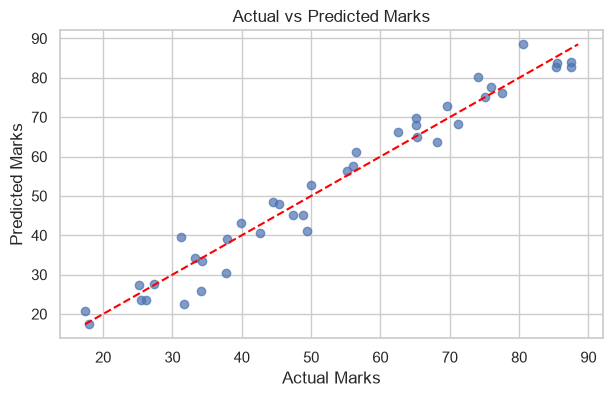

In [28]:
plt.figure(figsize=(7, 4))

plt.scatter(y_test, y_pred_sklearn, alpha=0.7)

min_value = min(y_test.min(), y_pred_sklearn.min())
max_value = max(y_test.max(), y_pred_sklearn.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    color="red",
    linestyle="--"
)

plt.xlabel("Actual Marks")
plt.ylabel("Predicted Marks")
plt.title("Actual vs Predicted Marks")

plt.grid(True)
plt.show()

### 8.2 Regression Line

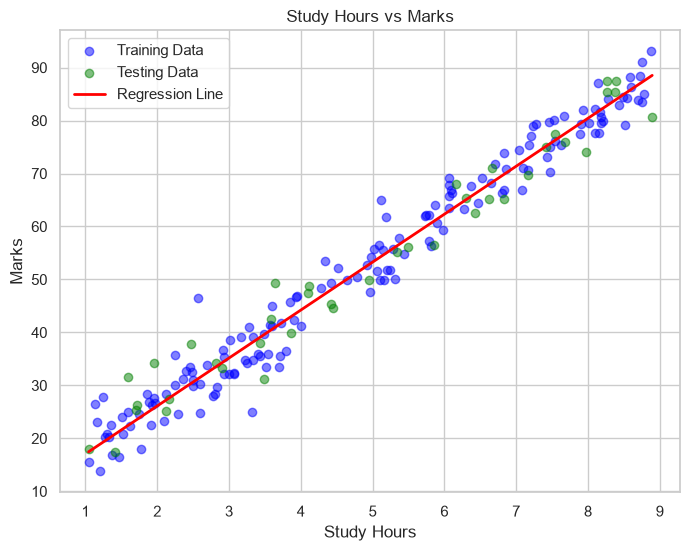

In [30]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_train,
    y_train,
    color="blue",
    alpha=0.5,
    label="Training Data"
)

plt.scatter(
    X_test,
    y_test,
    color="green",
    alpha=0.5,
    label="Testing Data"
)

x_line = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
y_line = sklearn_model.predict(x_line)

plt.plot(
    x_line,
    y_line,
    color="red",
    linewidth=2,
    label="Regression Line"
)

plt.xlabel("Study Hours")
plt.ylabel("Marks")
plt.title("Study Hours vs Marks")
plt.legend()
plt.grid(True)
plt.show()

# 9 - Predict New Student Marks

### 9.1 Custom Prediction Function

In [31]:
def predict_marks(hours):

    input_data = np.array([[hours]])

    prediction = sklearn_model.predict(input_data)

    return prediction[0]

### 9.2 Cell Test Custom Prediction

In [34]:

new_students = np.array([
    [2],
    [4],
    [6],
    [8]
])

predictions = sklearn_model.predict(new_students)

prediction_df = pd.DataFrame({
    "Study Hours": new_students.ravel(),
    "Predicted Marks": predictions
})

prediction_df

,Study Hours,Predicted Marks
0,2,26.110501
1,4,44.215204
2,6,62.319908
3,8,80.424612


# 10 - Saved Trained Model

In [36]:
import joblib
import os

os.makedirs("models", exist_ok=True)

joblib.dump(
    sklearn_model,
    "models/linear_regression_model.pkl"
)

print("Model saved successfully!")

# Load Model

loaded_model = joblib.load(
    "models/linear_regression_model.pkl"
)

new_prediction = loaded_model.predict(
    np.array([[7]])
)

print(f"\nPredicted marks for 7 hours: {new_prediction[0]:.2f}")

Model saved successfully!

Predicted marks for 7 hours: 71.37
